In [ ]:
import math
import re
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier

from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, roc_curve, roc_auc_score

import pickle

#Loading the dataset
!wget -q -O cardiovascular_dataset.zip \
"https://www.kaggle.com/api/v1/datasets/download/sulianova/cardiovascular-disease-dataset"

import zipfile

with zipfile.ZipFile(
    "cardiovascular_dataset.zip",
    "r"
) as zip_ref:

    zip_ref.extractall("cardiovascular_data")

df = pd.read_csv(
    "cardiovascular_data/cardio_train.csv",
    sep=";"
)

list(df.columns)

['id',
 'age',
 'gender',
 'height',
 'weight',
 'ap_hi',
 'ap_lo',
 'cholesterol',
 'gluc',
 'smoke',
 'alco',
 'active',
 'cardio']

# **Dataset exploration**

In [ ]:
pd.concat([df.head(5), df.sample(5), df.tail(5)])

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0
19785,28249,19576,1,177,132.0,130,80,2,3,0,0,0,1
34133,48764,22645,1,173,68.0,180,100,1,2,0,0,1,0
13644,19476,21135,1,163,78.0,140,90,2,1,0,0,1,1
41209,58891,19934,2,168,68.0,120,80,1,1,0,0,1,0
43657,62379,21083,2,165,84.0,170,100,1,2,0,0,0,0


In [ ]:
df.describe(include='all').T

,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.865814,2467.251667,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.349571,0.476838,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.205690,14.395757,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817286,154.011419,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.366871,0.680250,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226457,0.572270,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088129,0.283484,0.0,0.00,0.0,0.00,1.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [ ]:
#Preprocessing
TARGET = 'cardio'

INPUT_FEATURES = [
    'id', 'age', 'gender', 'height', 'weight',
    'ap_hi', 'ap_lo', 'cholesterol', 'gluc',
    'smoke', 'alco', 'active'
]

# Check the dataset
pd.DataFrame(
    [df.nunique(), df.dtypes],
    index=['Unique Values', 'Data Types']
)

# Check for duplicate rows
duplicates = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicates}")

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print(f"Dataset shape after removing duplicates: {df.shape}")

# Check for missing values
pd.DataFrame(
    {
        "Count": df.isna().sum().sort_values(ascending=False),
        "percent %": 100.0 * df.isna().sum().sort_values(ascending=False) / len(df),
    }
).T

# Check categorical values for consistency
for col in ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index())

# Function for removing unwanted features
def drop_unwanted_features(df, feature_to_drop):
    print(f"\nDropping feature: {feature_to_drop}")

    if feature_to_drop in df.columns:
        df = df.drop(columns=[feature_to_drop])

    if feature_to_drop in INPUT_FEATURES:
        INPUT_FEATURES.remove(feature_to_drop)

    return df

# Remove ID because it is an identifier, not a predictive feature
df = drop_unwanted_features(df, 'id')

list(df.columns)

Number of duplicate rows: 24
Dataset shape after removing duplicates: (69976, 12)

gender
gender
1    45509
2    24467
Name: count, dtype: int64

cholesterol
cholesterol
1    52361
2     9549
3     8066
Name: count, dtype: int64

gluc
gluc
1    59455
2     5190
3     5331
Name: count, dtype: int64

smoke
smoke
0    63807
1     6169
Name: count, dtype: int64

alco
alco
0    66212
1     3764
Name: count, dtype: int64

active
active
0    13735
1    56241
Name: count, dtype: int64

cardio
cardio
0    35004
1    34972
Name: count, dtype: int64

Dropping feature: id


['age',
 'gender',
 'height',
 'weight',
 'ap_hi',
 'ap_lo',
 'cholesterol',
 'gluc',
 'smoke',
 'alco',
 'active',
 'cardio']

In [ ]:
# Check blood pressure consistency

invalid_bp = df['ap_lo'] >= df['ap_hi']

print(
    f"Records where diastolic BP >= systolic BP: "
    f"{invalid_bp.sum()}"
)

# Remove invalid BP records
df = df[df['ap_lo'] < df['ap_hi']].copy()

print(f"Dataset shape after BP cleaning: {df.shape}")

Records where diastolic BP >= systolic BP: 1236
Dataset shape after BP cleaning: (68740, 12)


In [ ]:
#Feature engineering
df['age_years'] = (df['age'] / 365).round().astype(int)
df['height_m'] = df['height'] / 100
df['bmi'] = df['weight'] / (df['height_m'] ** 2)
df['pulse_pressure'] = df['ap_hi'] - df['ap_lo']
df['health_index'] = (df['active'] * 1) - (df['smoke'] * 0.5) - (df['alco'] * 0.5)
df['cholesterol_gluc_interaction'] = df['cholesterol'] * df['gluc']
df['map'] = (df['ap_hi'] + 2 * df['ap_lo']) / 3

df['bmi_category'] = pd.cut(
    df['bmi'],
    bins=[0, 18.5, 25, 30, np.inf],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese']
)

def bp_category(row):
    systolic = row['ap_hi']
    diastolic = row['ap_lo']
    if systolic < 120 and diastolic < 80:
        return 'Normal'
    elif systolic < 130 and diastolic < 80:
        return 'Elevated'
    elif systolic < 140 or diastolic < 90:
        return 'Stage 1'
    else:
        return 'Stage 2'

df['hypertension_stage'] = df.apply(bp_category, axis=1)

new_features = [
    'age_years', 'bmi', 'pulse_pressure', 'health_index',
    'cholesterol_gluc_interaction', 'map', 'bmi_category', 'hypertension_stage'
]
INPUT_FEATURES = INPUT_FEATURES + [f for f in new_features if f not in INPUT_FEATURES]

df = drop_unwanted_features(df, 'age')
df = drop_unwanted_features(df, 'height')

INPUT_FEATURES = [
    'gender', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc',
    'smoke', 'alco', 'active', 'age_years', 'bmi', 'pulse_pressure',
    'health_index', 'cholesterol_gluc_interaction', 'map',
    'bmi_category', 'hypertension_stage'
]


Dropping feature: age

Dropping feature: height


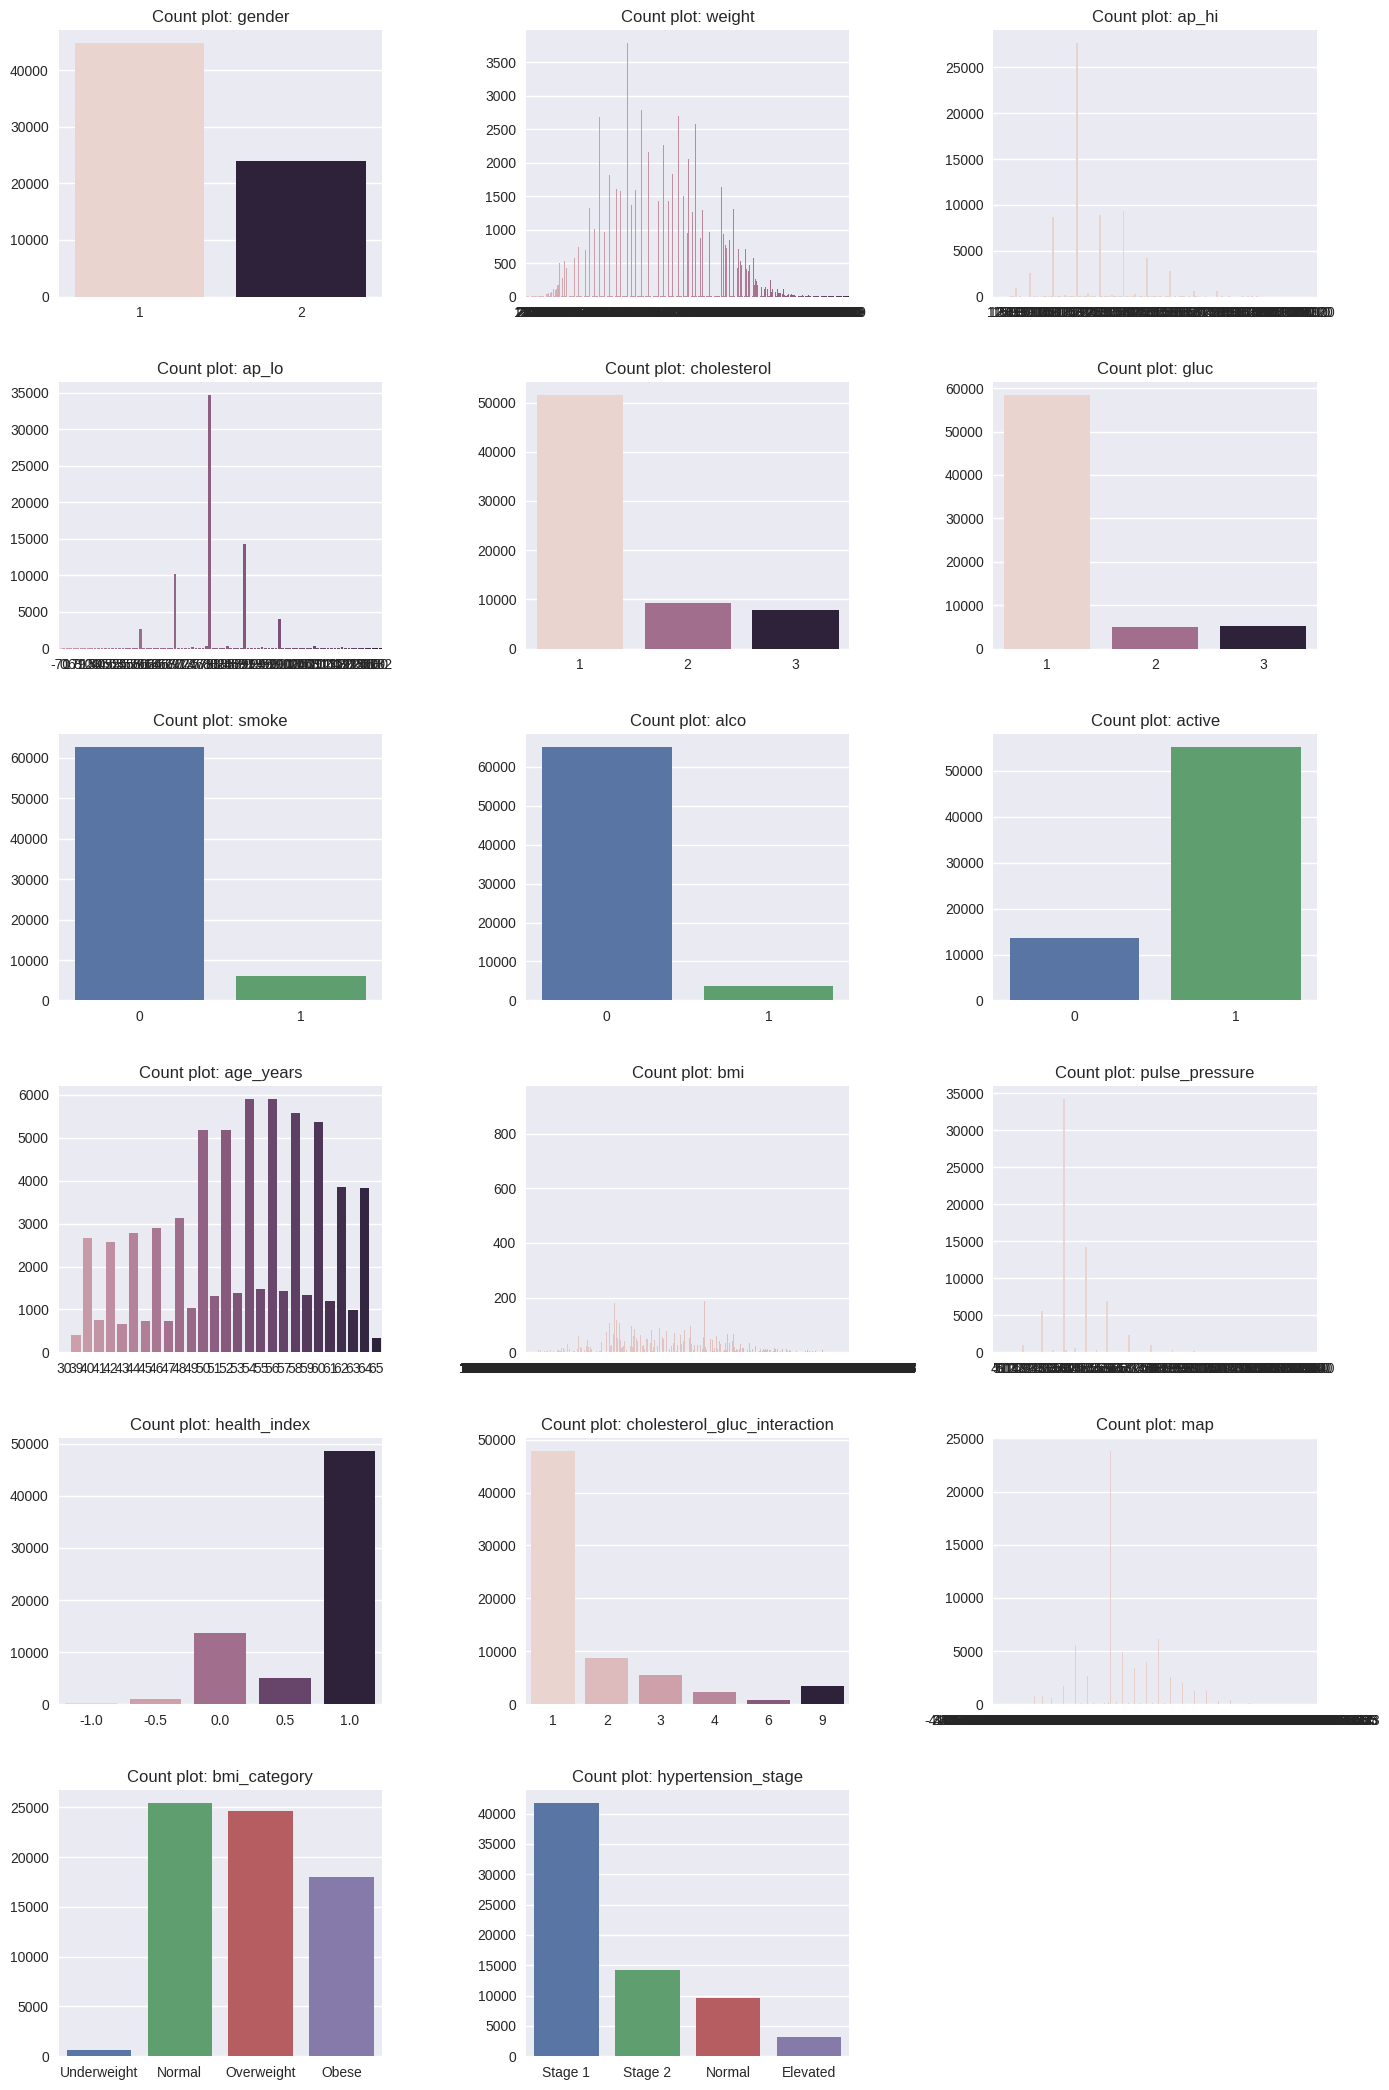

In [ ]:
plt.style.use(plt.style.available[12])

N_COLS = 3
N_ROWS = math.ceil(len(INPUT_FEATURES) / N_COLS)

plt.figure(figsize=(14, 3.5 * N_ROWS))

for i, cat_feature in enumerate(INPUT_FEATURES):
    plt.subplot(N_ROWS, N_COLS, i+1)
    plt.title(f"Count plot: {cat_feature}")
    sns.countplot(data=df, x=cat_feature, hue=cat_feature, legend=False)
    plt.ylabel("")
    plt.xlabel('')

plt.tight_layout(h_pad=3.0, w_pad=2.0)

plt.show()


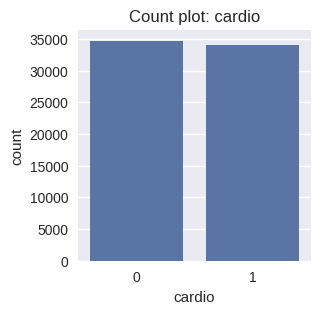

In [ ]:
plt.figure(figsize=(3,3))
plt.title(f"Count plot: {TARGET}")
sns.countplot(df, x=TARGET)
plt.show()

In [ ]:
print(df.shape)

(68740, 19)


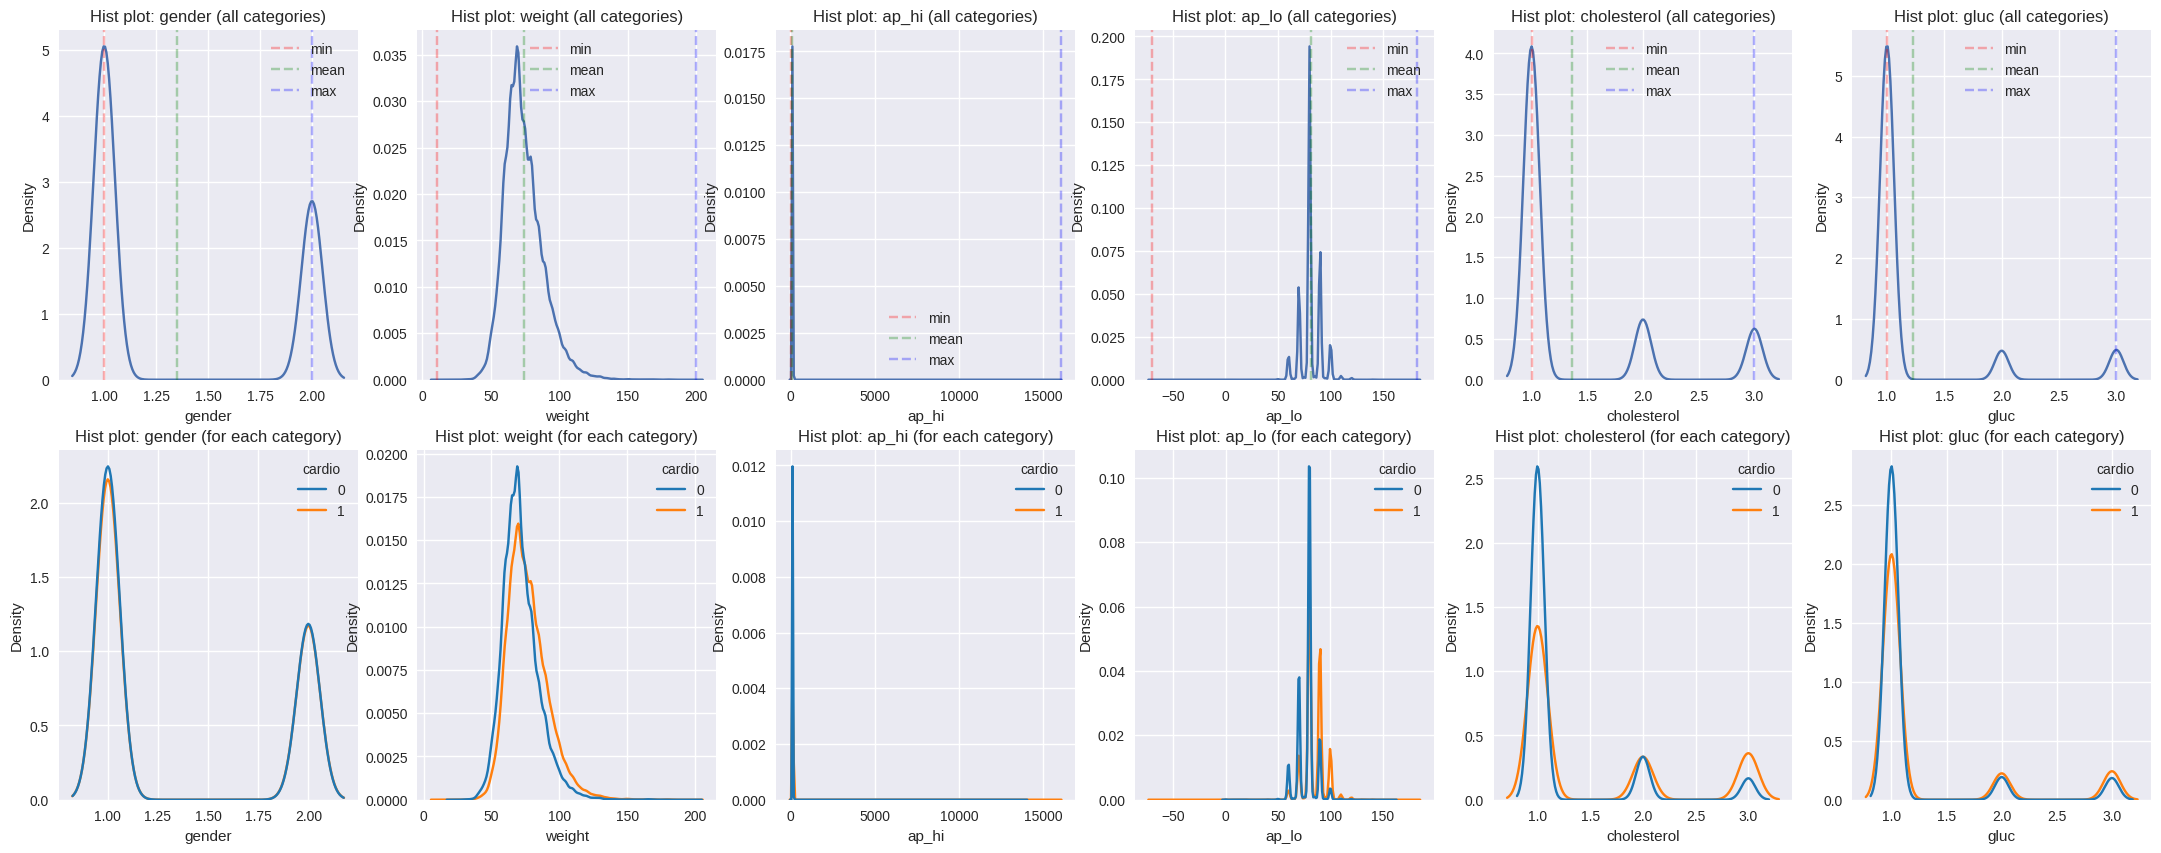

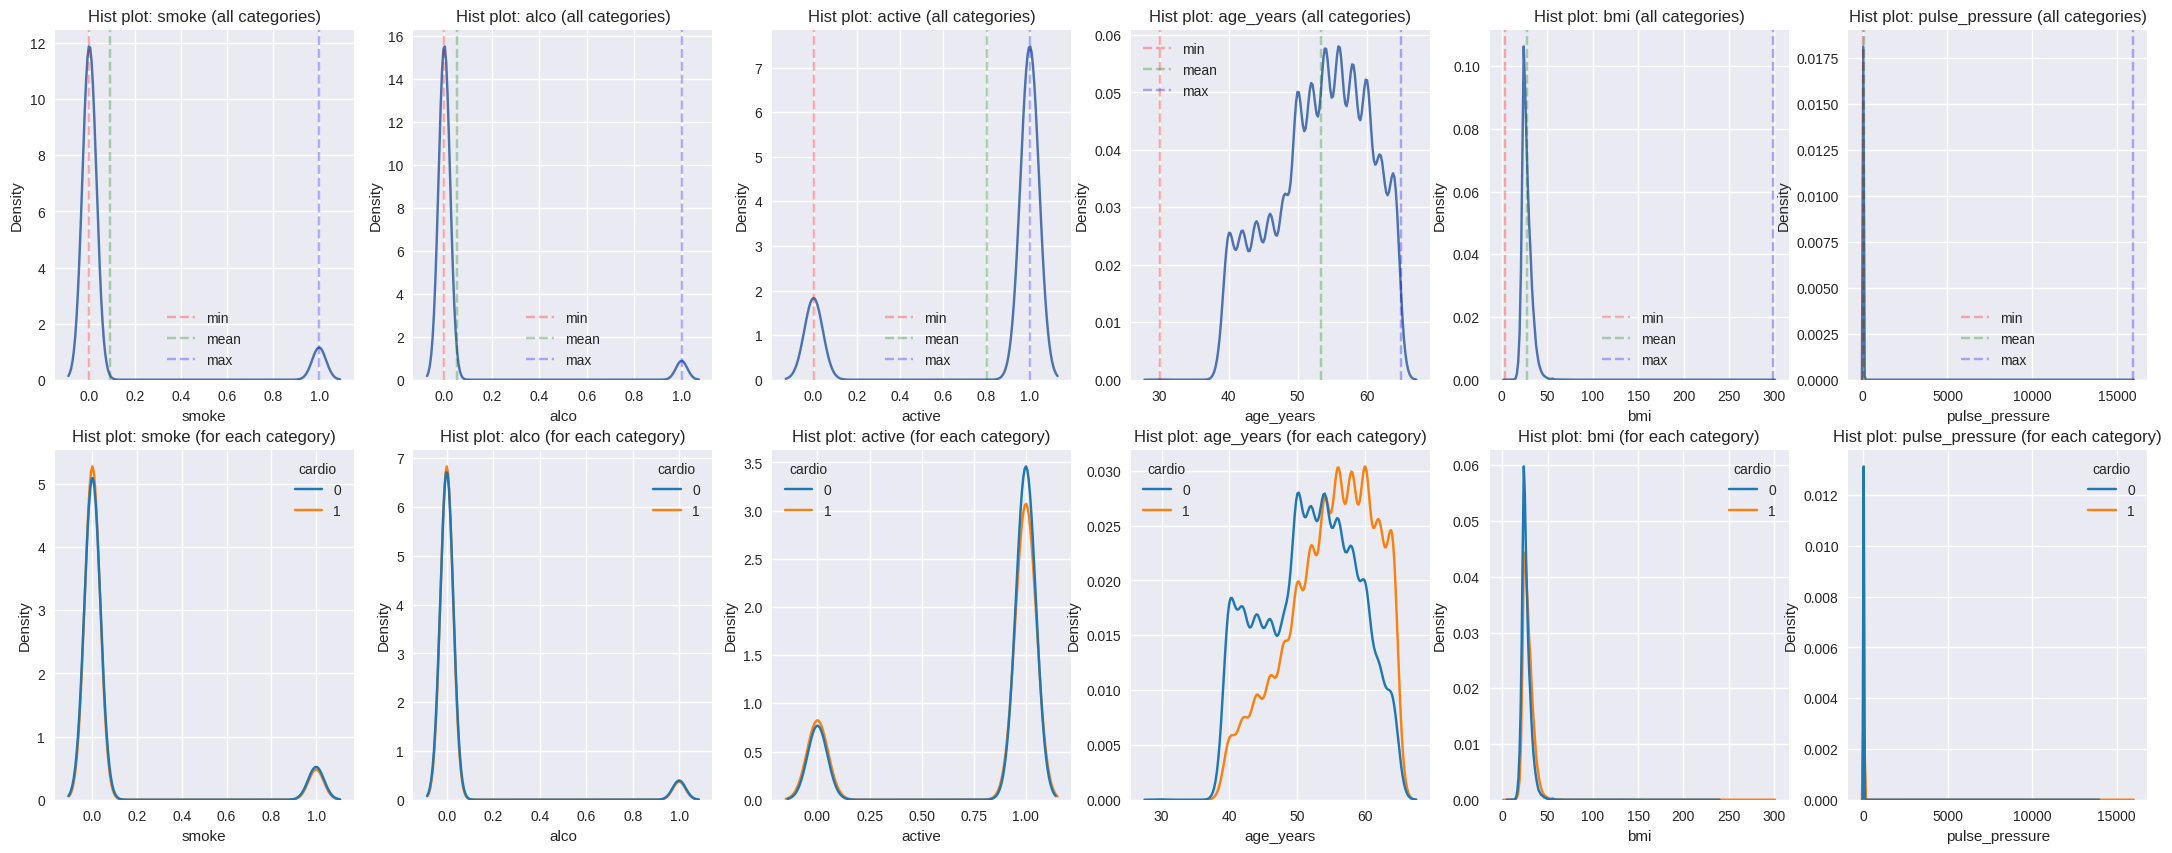

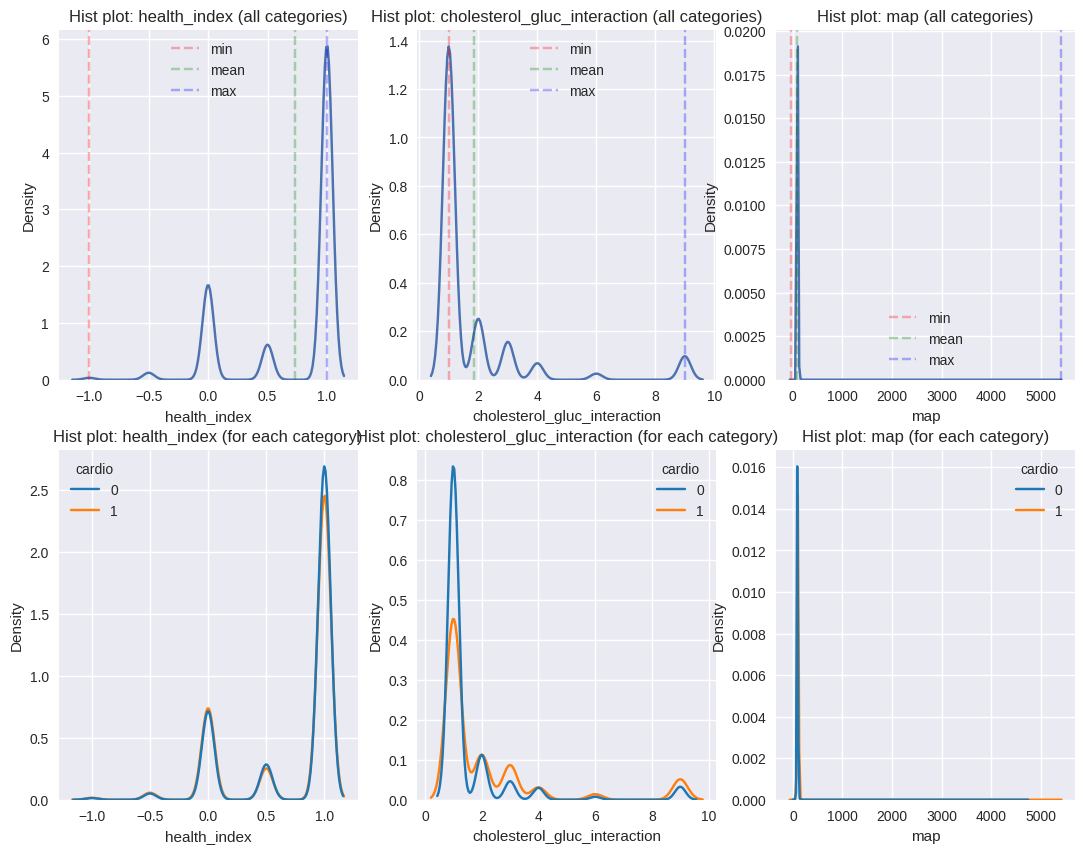

In [ ]:
ROW_WIDTH = 6
temp = 0

numeric_features = [
    feature for feature in INPUT_FEATURES
    if df[feature].dtype in ['int64', 'float64', 'int32', 'float32']
    and feature not in ['bmi_category', 'hypertension_stage']
]

for num_feature in numeric_features:
    if temp == 0:
        plt.figure(figsize=(27,10))

    plt.subplot(2,ROW_WIDTH, temp + 1)
    plt.title(f"Hist plot: {num_feature} (all categories)")
    sns.kdeplot(df, x=num_feature, )

    plt.axvline(x= df[num_feature].min() , label="min", color='r', linestyle='--', alpha = 0.3)
    plt.axvline(x= df[num_feature].mean() , label="mean", color='g', linestyle='--', alpha = 0.3)
    plt.axvline(x= df[num_feature].max() , label="max", color='b', linestyle='--', alpha = 0.3)

    plt.legend()


    plt.subplot(2,ROW_WIDTH, (temp + 1) + ROW_WIDTH)
    plt.title(f"Hist plot: {num_feature} (for each category)")
    sns.kdeplot(df, x=num_feature, hue=TARGET, palette='tab10')

    if temp == ROW_WIDTH - 1:
        plt.show()

    temp = (temp + 1) % ROW_WIDTH

if temp != ROW_WIDTH - 1:
    plt.show()

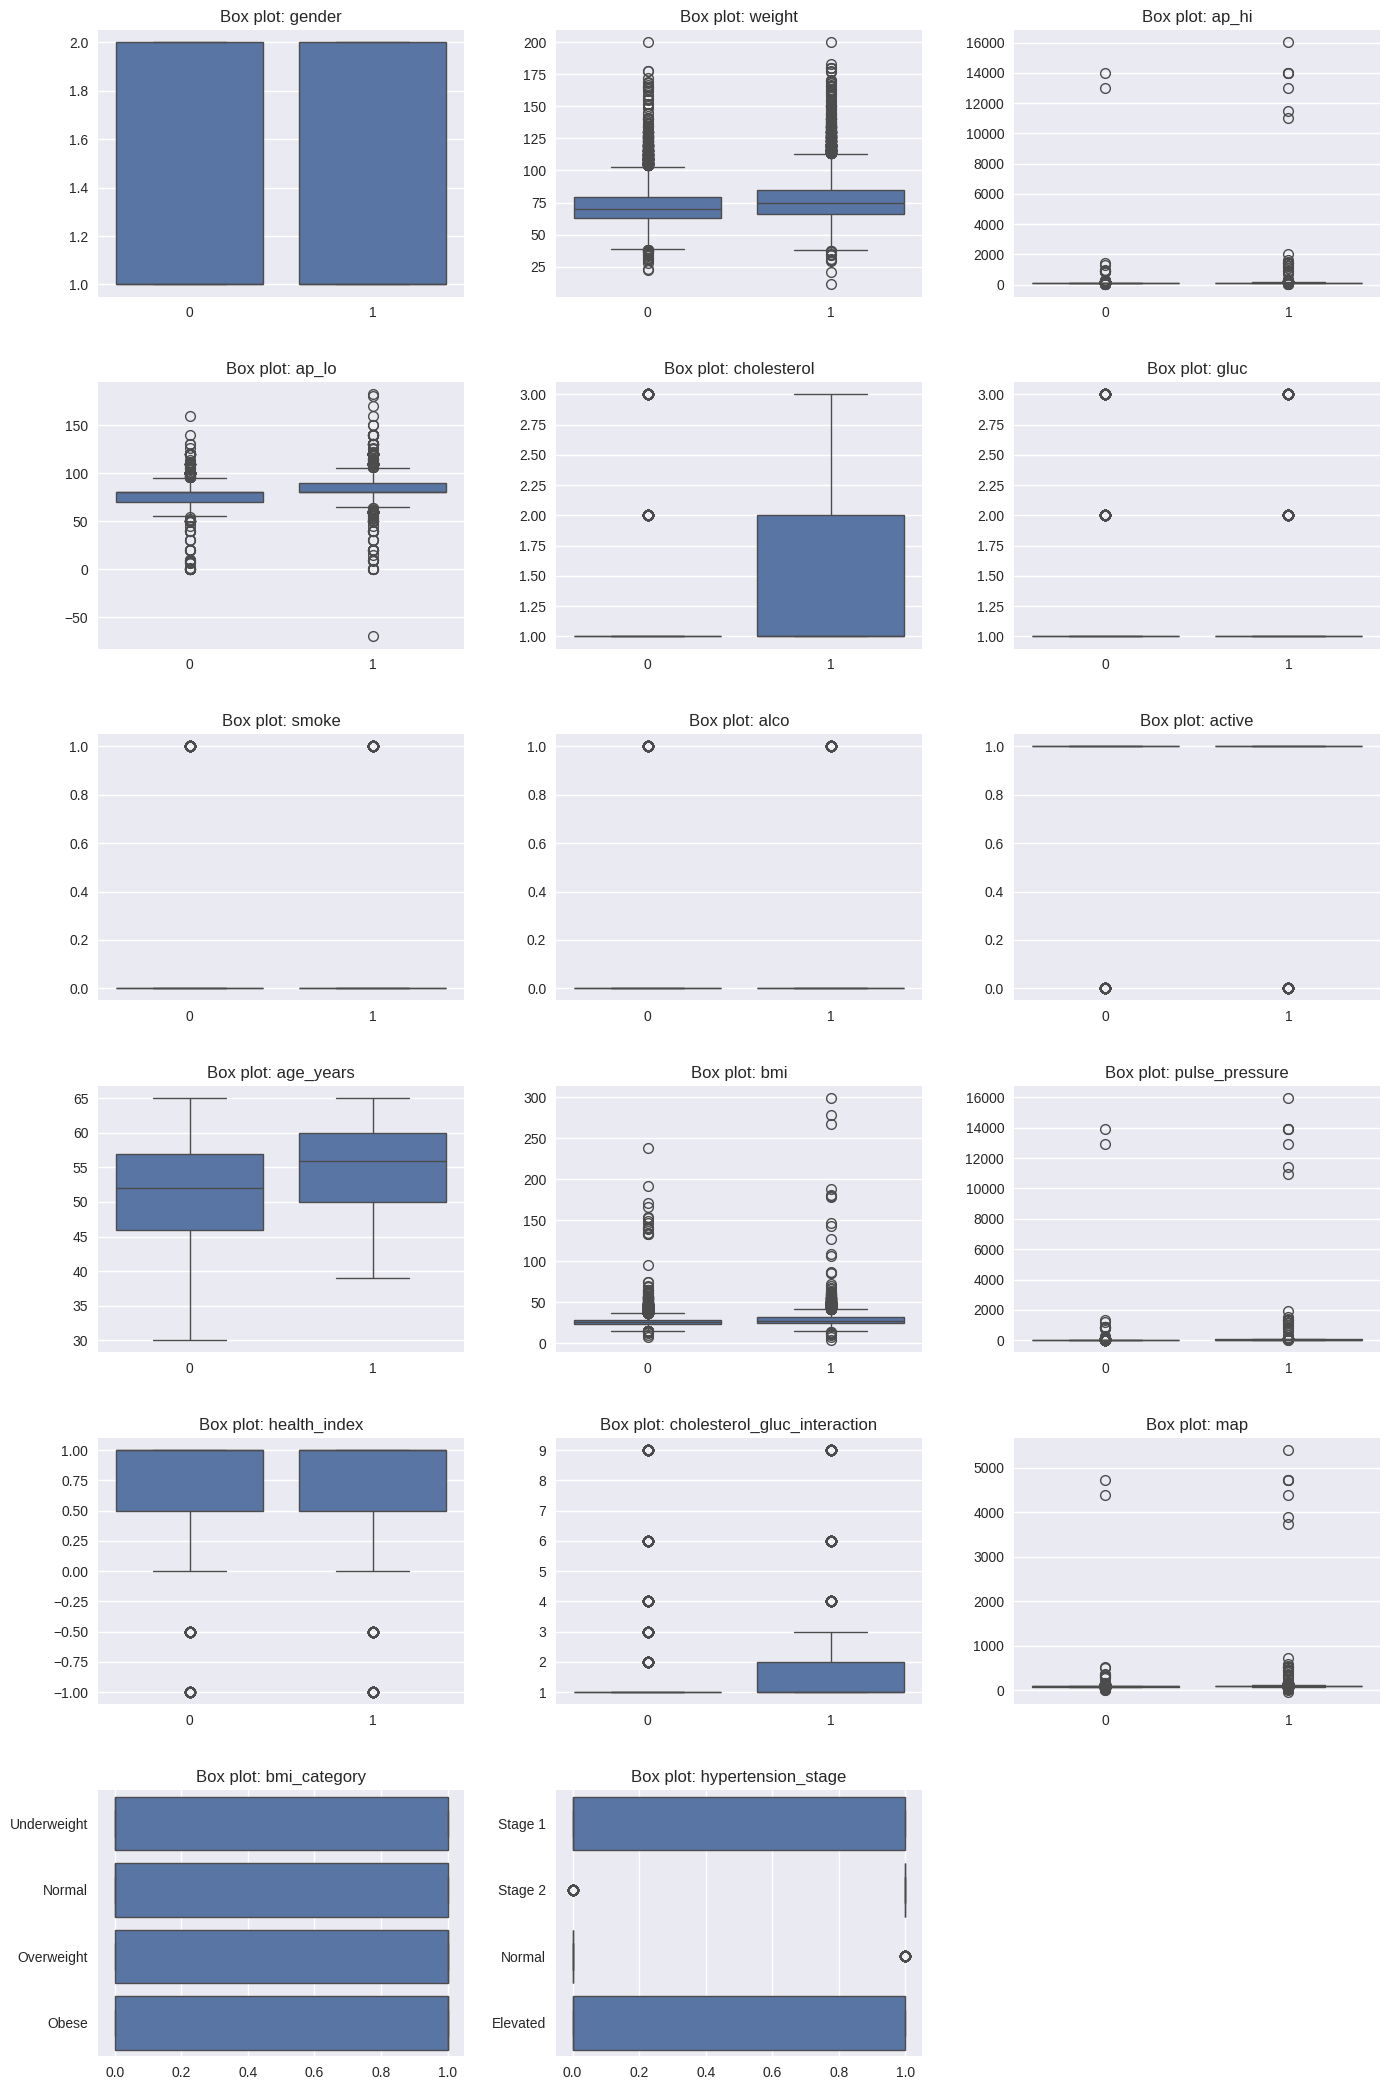

In [ ]:
N_COLS = 3
N_ROWS = math.ceil(len(INPUT_FEATURES) / N_COLS)

plt.figure(figsize=(14, 3.5 * N_ROWS))

for i, feature in enumerate(INPUT_FEATURES):
    plt.subplot(N_ROWS, N_COLS, i+1)
    plt.title(f"Box plot: {feature}")
    sns.boxplot(df, x=TARGET, y=feature)
    plt.ylabel("")
    plt.xlabel('')

plt.tight_layout(h_pad=3.0, w_pad=2.0)
plt.show()

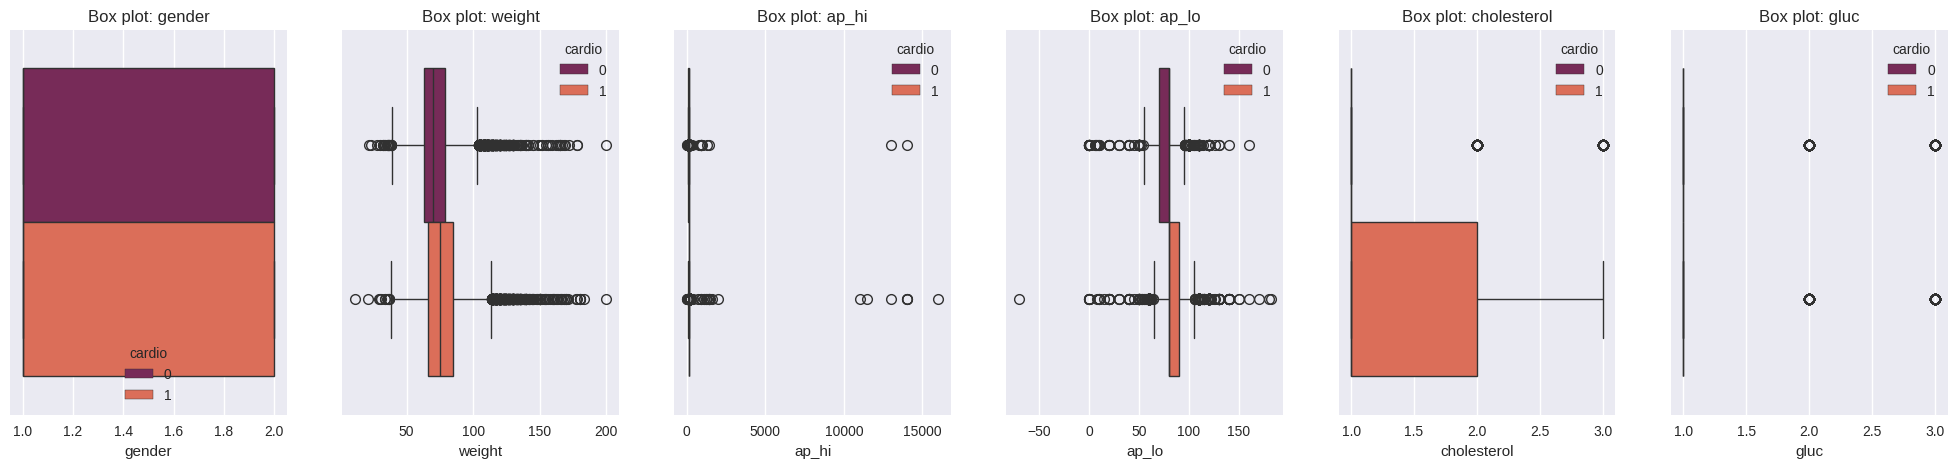

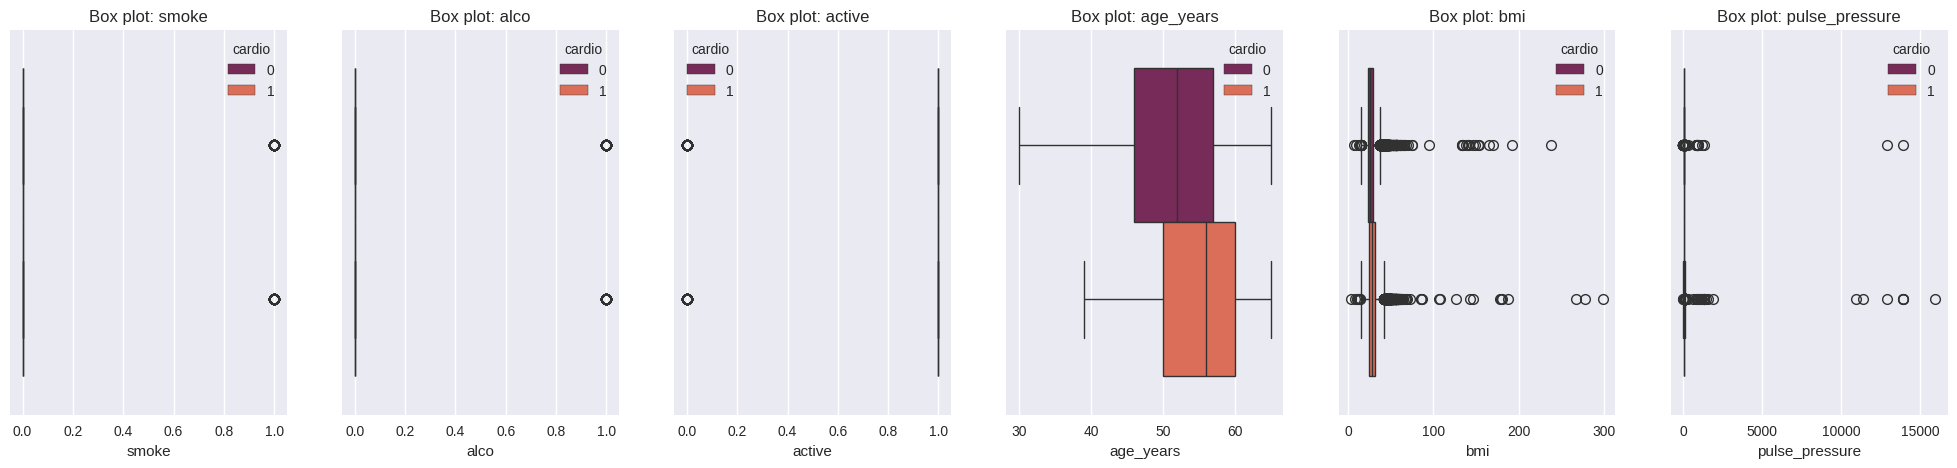

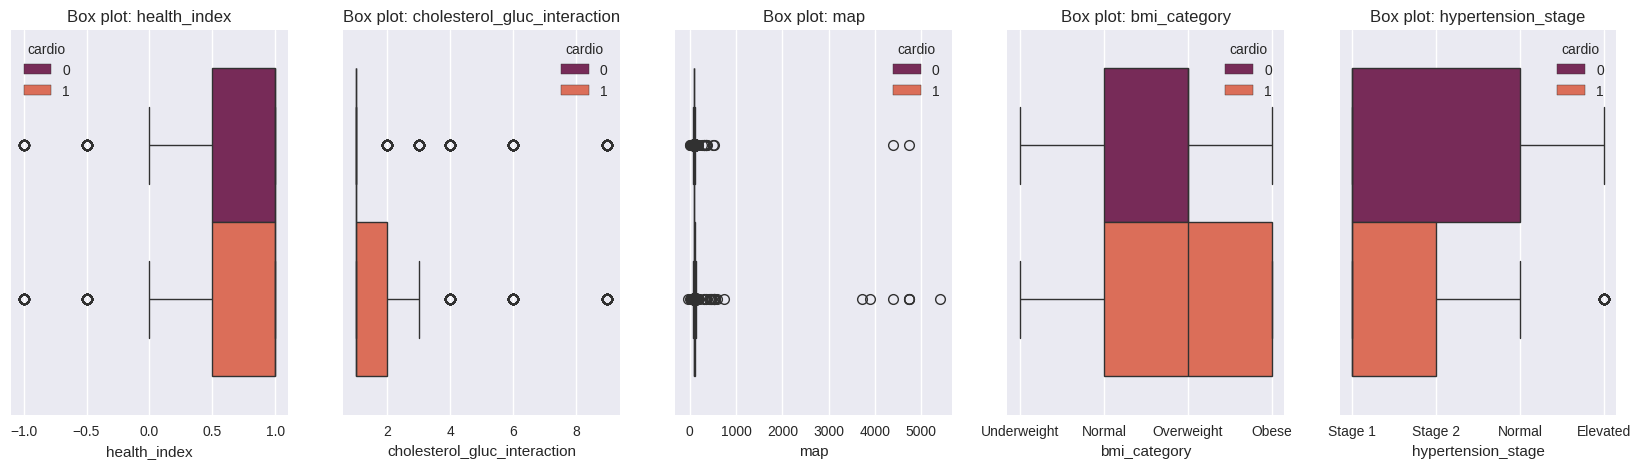

In [ ]:
#Outliers
def plot_box(features, hue):
    ROW_WIDTH = 6
    temp = 0

    for num_feature in features:
        if temp == 0:
            plt.figure(figsize=(25,5))

        plt.subplot(1,ROW_WIDTH, temp + 1)
        plt.title(f"Box plot: {num_feature}")
        sns.boxplot(df, x=num_feature, hue=hue, palette='rocket')

        if temp == ROW_WIDTH - 1:
            plt.show()

        temp = (temp + 1) % ROW_WIDTH

    if temp != ROW_WIDTH - 1:
        plt.show()

plot_box(INPUT_FEATURES, TARGET)

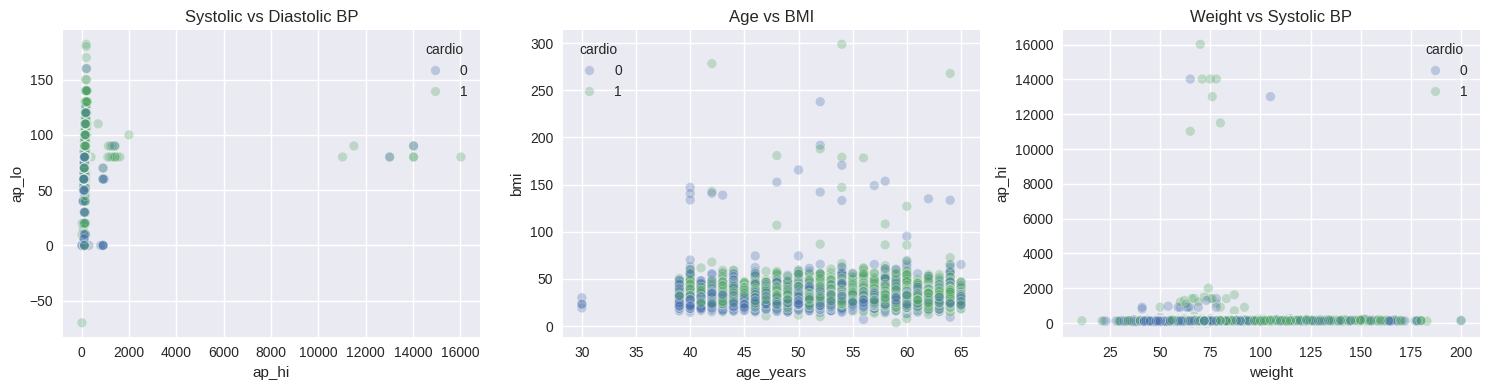

In [ ]:
#Scatter plots
plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
sns.scatterplot(df, x='ap_hi', y='ap_lo', hue=TARGET, alpha=0.3)
plt.title("Systolic vs Diastolic BP")

plt.subplot(1,3,2)
sns.scatterplot(df, x='age_years', y='bmi', hue=TARGET, alpha=0.3)
plt.title("Age vs BMI")

plt.subplot(1,3,3)
sns.scatterplot(df, x='weight', y='ap_hi', hue=TARGET, alpha=0.3)
plt.title("Weight vs Systolic BP")

plt.tight_layout()
plt.show()

In [ ]:
def find_iqr_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return (series < lower) | (series > upper)

# Create 'age_years' and 'height_m' columns if they don't exist
# This ensures that the features are available for the outlier detection loop.
# if 'age_years' not in df.columns:
#     df['age_years'] = (df['age'] / 365).round().astype(int)
# if 'height_m' not in df.columns:
#     df['height_m'] = df['height'] / 100


for feature in ['age_years', 'height_m', 'weight', 'ap_hi', 'ap_lo']:
    outliers = find_iqr_outliers(df[feature])

    print(
        f"{feature}: "
        f"{outliers.sum()} potential outliers "
        f"({100 * outliers.mean():.2f}%)"
    )

age_years: 4 potential outliers (0.01%)
height_m: 506 potential outliers (0.74%)
weight: 1746 potential outliers (2.54%)
ap_hi: 1058 potential outliers (1.54%)
ap_lo: 3570 potential outliers (5.19%)


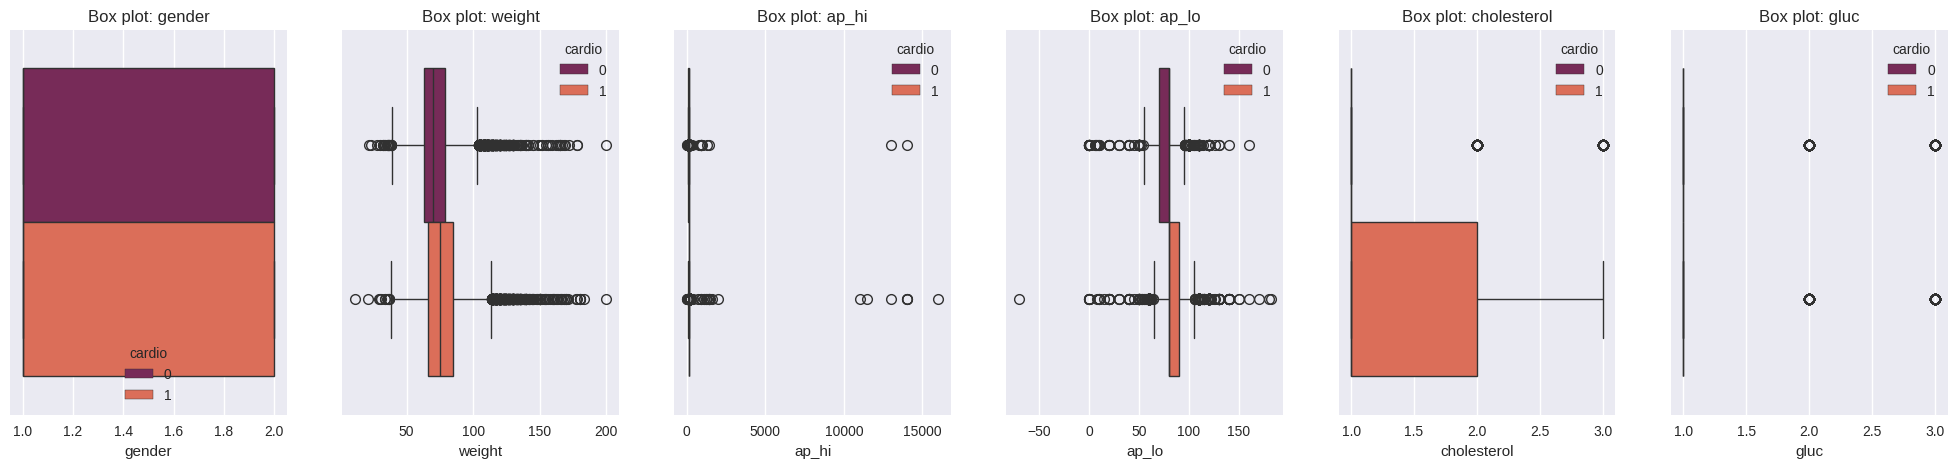

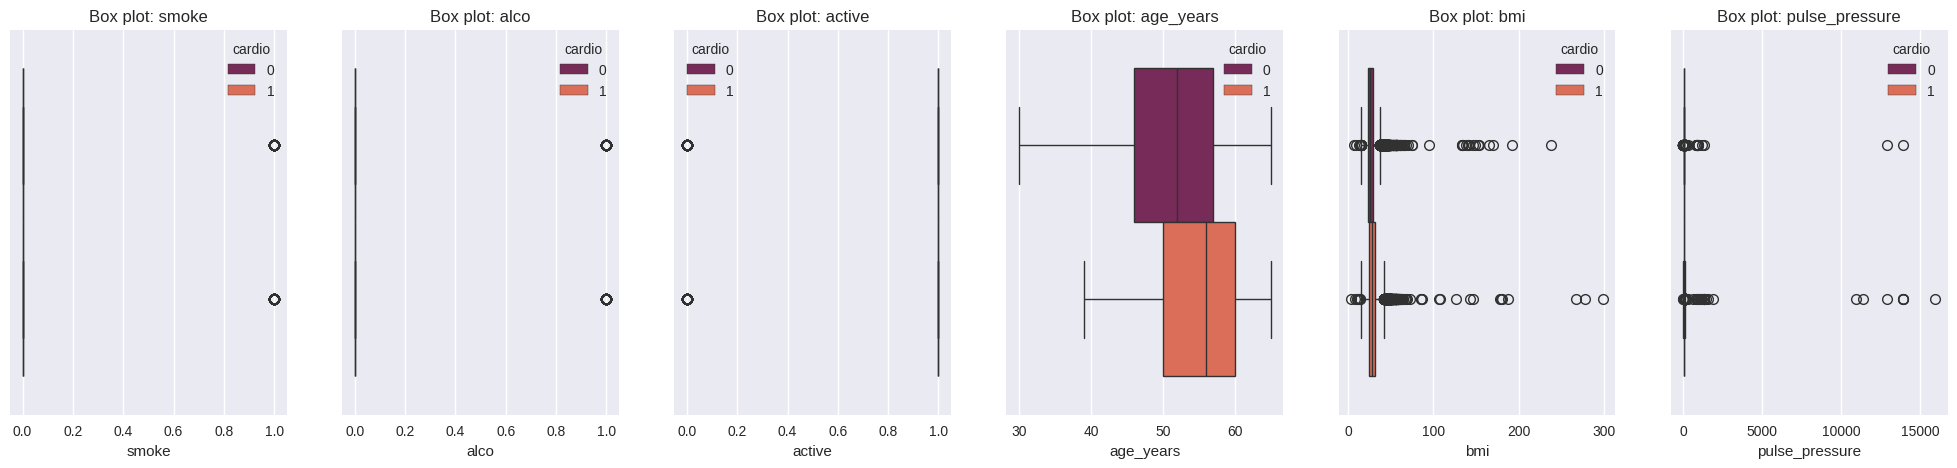

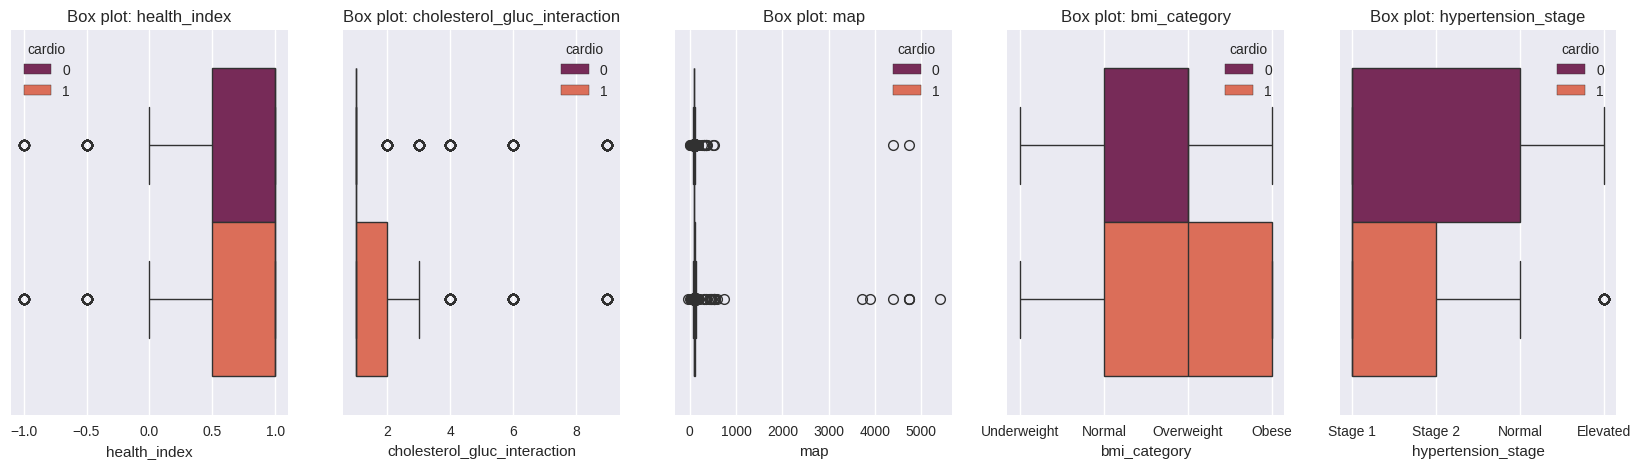

In [ ]:
plot_box(INPUT_FEATURES, TARGET)

In [ ]:
#Dataset splitting
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(TARGET, axis=1),
    df.loc[:, TARGET],
    test_size=0.20,
    random_state=1234,
    stratify=df[TARGET]
)

print(f"{X_train.shape= }")
print(f"{y_train.shape= }")
print(f"{X_test.shape= }")
print(f"{y_test.shape= }")

#Encoding categorical engineered features
CATEGORICAL_TO_ENCODE = ['bmi_category', 'hypertension_stage']

X_train_encoded = pd.get_dummies(X_train, columns=CATEGORICAL_TO_ENCODE, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=CATEGORICAL_TO_ENCODE, drop_first=True)

# Align test set columns to train set (handles any category missing from one split)
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

X_train.shape= (54992, 18)
y_train.shape= (54992,)
X_test.shape= (13748, 18)
y_test.shape= (13748,)


In [ ]:
# y_train.value_counts()

In [ ]:
# y_test.value_counts()

In [ ]:
# list(X_train.columns)

# dfsample, _ = train_test_split(
#     df,
#     test_size=0.9,
#     stratify=df["cardio"],
#     random_state=42
# )
# X_train,X_test, y_train, y_test = train_test_split(
#     df.drop(TARGET, axis=1),
#     df.loc[:, TARGET],
#     test_size=0.25,
#     random_state=1234,
#     stratify=df.loc[:, TARGET],
#   )

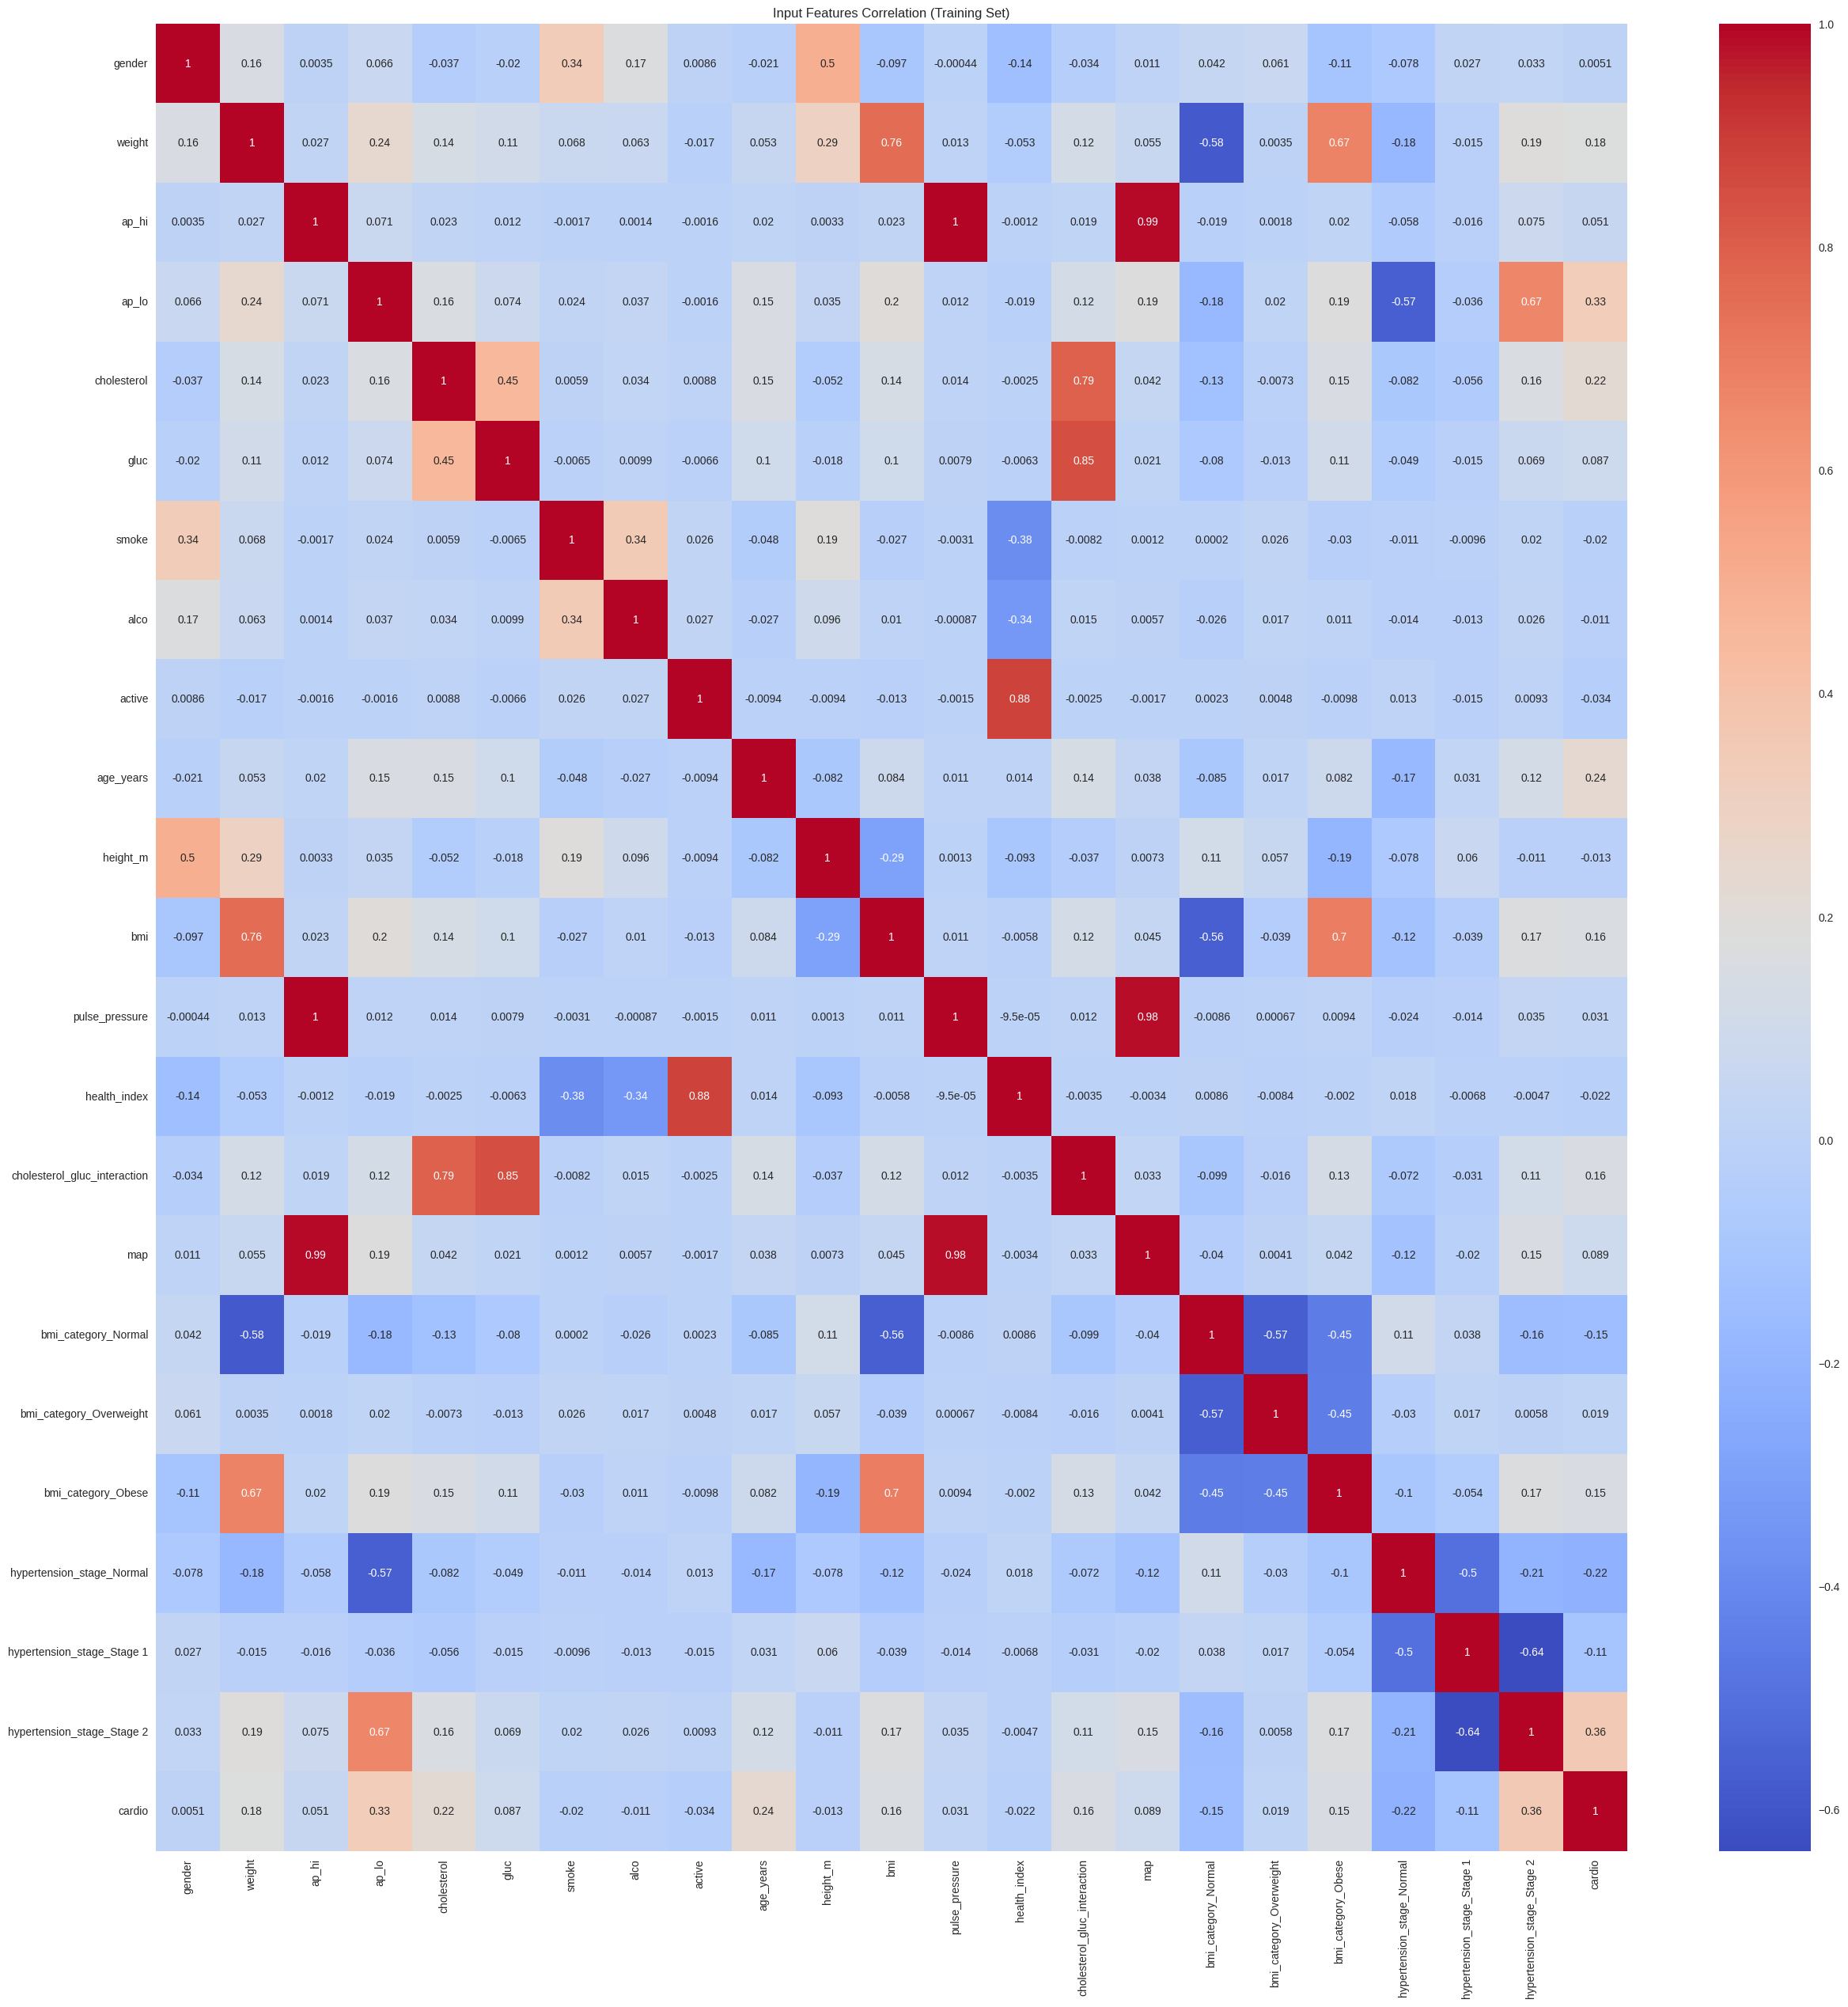

gender                             : F-value =    1.431, p-value = 0.2316
weight                             : F-value = 1794.274, p-value = 0.0000
ap_hi                              : F-value =  142.839, p-value = 0.0000
ap_lo                              : F-value = 6829.579, p-value = 0.0000
cholesterol                        : F-value = 2796.949, p-value = 0.0000
gluc                               : F-value =  415.941, p-value = 0.0000
smoke                              : F-value =   21.059, p-value = 0.0000
alco                               : F-value =    6.405, p-value = 0.0114
active                             : F-value =   65.520, p-value = 0.0000
age_years                          : F-value = 3310.044, p-value = 0.0000
height_m                           : F-value =    9.374, p-value = 0.0022
bmi                                : F-value = 1484.890, p-value = 0.0000
pulse_pressure                     : F-value =   53.380, p-value = 0.0000
health_index                       : F

In [ ]:
#Correlation Matrix (training set only)
plt.figure(figsize=(30, 30))
plt.title("Input Features Correlation (Training Set)")

sns.heatmap(
    pd.concat([X_train_encoded, y_train], axis=1).corr(),
    annot=True,
    cmap='coolwarm'
)
plt.show()

#Feature selection (ANOVA F-test on training set only)
f_values, p_values = f_classif(X_train_encoded, y_train)

for feature, f_val, p_val in zip(X_train_encoded.columns, f_values, p_values):
    print(f"{feature:35s}: F-value = {f_val:8.3f}, p-value = {p_val:.4f}")

In [ ]:
#Finalize selected features
ALPHA = 0.05
SELECTED_FEATURES = [
    feature for feature, p in zip(X_train_encoded.columns, p_values) if p < ALPHA
]

print(f"Selected {len(SELECTED_FEATURES)} of {X_train_encoded.shape[1]} features at alpha={ALPHA}:")
print(SELECTED_FEATURES)

X_train_selected = X_train_encoded[SELECTED_FEATURES]
X_test_selected = X_test_encoded[SELECTED_FEATURES]

Selected 21 of 22 features at alpha=0.05:
['weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'height_m', 'bmi', 'pulse_pressure', 'health_index', 'cholesterol_gluc_interaction', 'map', 'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese', 'hypertension_stage_Normal', 'hypertension_stage_Stage 1', 'hypertension_stage_Stage 2']


In [ ]:
#Scaling
df.describe()

,gender,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,height_m,bmi,pulse_pressure,health_index,cholesterol_gluc_interaction,map
count,68764.000000,68764.000000,68764.000000,68764.000000,68764.000000,68764.000000,68764.000000,68764.000000,68764.000000,68764.000000,68764.000000,68764.000000,68764.000000,68764.000000,68764.000000,68764.000000,68764.000000
mean,1.348613,74.113846,128.840440,81.245230,1.364668,1.225583,0.087880,0.053342,0.803458,0.494765,53.325985,1.643598,27.521579,47.595210,0.732847,1.847231,97.110300
std,0.476535,14.330819,155.203641,9.693745,0.678883,0.571448,0.283123,0.224716,0.397386,0.499976,6.768119,0.081907,6.067645,154.768117,0.443137,1.873088,52.622326
min,1.000000,11.000000,12.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,30.000000,0.550000,3.471784,4.000000,-1.000000,1.000000,-41.666667
25%,1.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,48.000000,1.590000,23.875115,40.000000,0.500000,1.000000,93.333333
50%,1.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,54.000000,1.650000,26.346494,40.000000,1.000000,1.000000,93.333333
75%,2.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000,58.000000,1.700000,30.119376,50.000000,1.000000,2.000000,103.333333
max,2.000000,200.000000,16020.000000,182.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000,65.000000,2.500000,298.666667,15940.000000,1.000000,9.000000,5393.333333


In [ ]:
# Scaling (deferred — will fit on X_train_selected only, then transform both sets)
min_max_scaler = MinMaxScaler()
exclude = ['gender', 'gluc', 'alco', 'smoke', 'cholesterol', 'active']  # binary/ordinal — left unscaled
cols_to_scale = [col for col in X_train_selected.columns if col not in exclude]
X_train_selected[cols_to_scale] = min_max_scaler.fit_transform(X_train_selected[cols_to_scale])
X_test_selected[cols_to_scale] = min_max_scaler.transform(X_test_selected[cols_to_scale])

df.head()

/tmp/ipykernel_1045/263186950.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_train_selected[cols_to_scale] = min_max_scaler.fit_transform(X_train_selected[cols_to_scale])
/tmp/ipykernel_1045/263186950.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_test_selected[cols_to_scale] = min_max_scaler.transform(X_test_selected[cols_to_scale])


,gender,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,height_m,bmi,pulse_pressure,health_index,cholesterol_gluc_interaction,map,bmi_category,hypertension_stage
0,2,62.0,110,80,1,1,0,0,1,0,50,1.68,21.967120,30,1.0,1,90.000000,Normal,Stage 1
1,1,85.0,140,90,3,1,0,0,1,1,55,1.56,34.927679,50,1.0,3,106.666667,Obese,Stage 2
2,1,64.0,130,70,3,1,0,0,0,1,52,1.65,23.507805,60,0.0,3,90.000000,Normal,Stage 1
3,2,82.0,150,100,1,1,0,0,1,1,48,1.69,28.710479,50,1.0,1,116.666667,Overweight,Stage 2
4,1,56.0,100,60,1,1,0,0,0,0,48,1.56,23.011177,40,0.0,1,73.333333,Normal,Normal


In [ ]:
df.describe()

,gender,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,height_m,bmi,pulse_pressure,health_index,cholesterol_gluc_interaction,map
count,68740.000000,68740.000000,68740.000000,68740.000000,68740.000000,68740.000000,68740.000000,68740.000000,68740.000000,68740.000000,68740.000000,68740.000000,68740.000000,68740.000000,68740.000000,68740.000000,68740.000000
mean,1.348691,74.116693,128.843672,81.245810,1.364795,1.225662,0.087911,0.053360,0.803448,0.494836,53.326244,1.643597,27.522684,47.597862,0.732812,1.847527,97.111764
std,0.476559,14.332302,155.230633,9.695316,0.678967,0.571532,0.283167,0.224753,0.397394,0.499977,6.768465,0.081918,6.068357,154.795068,0.443156,1.873348,52.631440
min,1.000000,11.000000,12.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,30.000000,0.550000,3.471784,4.000000,-1.000000,1.000000,-41.666667
25%,1.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,48.000000,1.590000,23.875115,40.000000,0.500000,1.000000,93.333333
50%,1.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,54.000000,1.650000,26.346494,40.000000,1.000000,1.000000,93.333333
75%,2.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000,58.000000,1.700000,30.119376,50.000000,1.000000,2.000000,103.333333
max,2.000000,200.000000,16020.000000,182.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000,65.000000,2.500000,298.666667,15940.000000,1.000000,9.000000,5393.333333


In [ ]:
#Model Def & Training
CACHE_MODELS_DIR_NAME = 'models_cache'
os.makedirs(CACHE_MODELS_DIR_NAME, exist_ok=True)

In [ ]:
import os
import pickle
import re

class CustomModel:
    def __init__(self, name, model, extra_train_param=None):
        self.name = str(name)
        self.model = model
        self.extra_train_param = extra_train_param

        self.y_train_hat = None
        self.y_test_hat = None
        self.feature_names = None  # هنخزن الأعمدة هنا

        self.load()

    def fit(self, x_train, y_train):
        if not getattr(self, "trained", False):
            if self.extra_train_param is None:
                self.model.fit(x_train, y_train)
            else:
                self.model.fit(x_train, y_train, **self.extra_train_param)

            self.feature_names = list(x_train.columns)

            self.trained = True
            self.save()

    def _align_features(self, X):
        if self.feature_names is not None:
            missing_cols = set(self.feature_names) - set(X.columns)
            extra_cols = set(X.columns) - set(self.feature_names)

            if missing_cols:
                raise ValueError(f"Missing columns in input: {missing_cols}")
            if extra_cols:

                X = X[self.feature_names]
            else:
                X = X[self.feature_names]

        return X

    def prdict_on_train(self, x_train):
        if self.y_train_hat is None:
            x_train = self._align_features(x_train)
            self.y_train_hat = self.model.predict(x_train)

    def prdict_on_test(self, x_test):
        if self.y_test_hat is None:
            x_test = self._align_features(x_test)
            self.y_test_hat = self.model.predict(x_test)

    def save(self):
        file_name = re.sub(r'\W+', '_', str(self.name).lower())
        file_path = CACHE_MODELS_DIR_NAME + '/' + file_name + '.pickle'
        with open(file_path, 'wb') as f:
            pickle.dump(
                {
                    "model": self.model,
                    "trained": self.trained,
                    "feature_names": self.feature_names
                },
                f
            )

    def load(self):
        file_name = re.sub(r'\W+', '_', str(self.name).lower())
        file_path = CACHE_MODELS_DIR_NAME + '/' + file_name + '.pickle'

        if os.path.exists(file_path):
            with open(file_path, 'rb') as f:
                data = pickle.load(f)
                self.model = data["model"]
                self.trained = data["trained"]
                self.feature_names = data.get("feature_names", None)
        else:
            self.trained = False

In [ ]:
models_list = []

# models_list.append(CustomModel("SVC rbf sigmoid", SVC( )))

models_list.append(CustomModel("Decision Tree max-depth=7", DecisionTreeClassifier(max_depth=7 )))
models_list.append(CustomModel("Decision Tree max-depth=10", DecisionTreeClassifier(max_depth=10,min_samples_split=7,min_samples_leaf=3,criterion='gini' )))


In [ ]:
for i, model in enumerate(models_list):
    print(f'{i+1:3d}/{len(models_list)}. Train {model.name}')
    model.fit(X_train_selected, y_train)

  1/2. Train Decision Tree max-depth=7
  2/2. Train Decision Tree max-depth=10
